# ethier2004

Generated by GreenSloth from this model's validations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mxlpy import scan

In [2]:
import math

import numpy as np
import sympy.physics.units as su

from mxlpy import Slider, SteadyStateModelBuilder

def _derived_Gamma_star(O, S_co):
    return (500 * O) / (S_co)

def _derived_Km(O, Kc, Ko):
    return Kc * (1 + (O) / (Ko))

def _derived_Gamma(Vcmax, Rd, Gamma_star, Km):
    return (Gamma_star * Vcmax + Km * Rd) / ((Vcmax) - (Rd))

def _derived_Vcmax_minus_Rd(Vcmax, Rd):
    return (Vcmax) - (Rd)

def _derived_J(Jmax, I, alpha, theta):
    return ((alpha * I + Jmax) - (np.pow(((alpha * I + Jmax) ** (2)) - (4 * theta * alpha * I * Jmax), 1 / 2))) / (2 * theta)

def _derived_Ac(Ci, gi, Vcmax, Rd, Gamma_star, Km):
    return (- (((Vcmax) - (Rd)) / (gi) + Ci + Km) + np.pow(((((Vcmax) - (Rd)) / (gi) + Ci + Km) ** (2)) - (4 * (-1) / (gi) * ((Rd * (Ci + Km)) - (Vcmax * ((Ci) - (Gamma_star))))), 1 / 2)) / (2 * (-1) / (gi))

def _derived_Aj(Ci, gi, Rd, Gamma_star, J):
    return (- ((((J) / (4)) - (Rd)) / (gi) + Ci + 2 * Gamma_star) + np.pow((((((J) / (4)) - (Rd)) / (gi) + Ci + 2 * Gamma_star) ** (2)) - (4 * (-1) / (gi) * ((Rd * (Ci + 2 * Gamma_star)) - ((J) / (4) * ((Ci) - (Gamma_star))))), 1 / 2)) / (2 * (-1) / (gi))

def _derived_An(Ac, Aj):
    return min(Ac, Aj)

def _derived_Cc(Ci, gi, An):
    return (Ci) - ((An) / (gi))

def _derived_Ac_inf(Ci, Vcmax, Rd, Gamma_star, Km):
    return ((((Ci) - (Gamma_star)) * Vcmax) / (Ci + Km)) - (Rd)

def _derived_Aj_inf(Ci, Rd, Gamma_star, J):
    return ((((Ci) - (Gamma_star)) * (J) / (4)) / (Ci + 2 * Gamma_star)) - (Rd)

def _derived_An_inf(Ac_inf, Aj_inf):
    return min(Ac_inf, Aj_inf)

def _derived_Ci_star(gi, Rd, Gamma_star):
    return (Gamma_star) - ((Rd) / (gi))

def _derived_Ac_app(Ci, Vcmax, Rd, Km_i, Ci_star):
    return ((((Ci) - (Ci_star)) * Vcmax) / (Ci + Km_i)) - (Rd)

def get_model() -> SteadyStateModelBuilder:
    m = SteadyStateModelBuilder()
    m.add_parameter("Ci", 300, unit=su.bar*su.micro, display_name="Ci", tex_name="C_i", slider=Slider(min="0", max="1600", step="5"))
    m.add_parameter("O", 210, unit=su.bar*su.milli, display_name="O", tex_name="O", slider=Slider(min="0", max="500", step="5"))
    m.add_parameter("gi", 0.2, unit=su.mol/(su.meter**2*su.second*su.bar), display_name="gi", tex_name="g_i", slider=Slider(min="0.01", max="1", step="0.01"))
    m.add_parameter("Vcmax", 56, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax", tex_name="V_{c,max}", slider=Slider(min="5", max="150", step="0.5"))
    m.add_parameter("Rd", 0.6, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Rd", tex_name="R_d", slider=Slider(min="0", max="5", step="0.05"))
    m.add_parameter("Jmax", 112, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Jmax", tex_name="J_{max}", slider=Slider(min="10", max="300", step="1"))
    m.add_parameter("I", 1500, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="I", tex_name="I", slider=Slider(min="0", max="2000", step="10"))
    m.add_parameter("alpha", 0.18, unit=None, display_name="alpha", tex_name="\\alpha")
    m.add_parameter("theta", 0.9, unit=None, display_name="theta", tex_name="\\theta")
    m.add_parameter("Kc", 274.22, unit=su.bar*su.micro, display_name="Kc", tex_name="K_c")
    m.add_parameter("Ko", 418.29, unit=su.bar*su.milli, display_name="Ko", tex_name="K_o")
    m.add_parameter("S_co", 2325.8, unit=None, display_name="S_co", tex_name="S_{c/o}")
    m.add_parameter("Km_i", 635.3, unit=su.bar*su.micro, display_name="Km_i", tex_name="K_m(CO_2)_i")
    m.add_derived("Gamma_star", _derived_Gamma_star, args=["O", "S_co"], unit=su.bar*su.micro, display_name="Gamma_star", tex_name="\\Gamma^*")
    m.add_derived("Km", _derived_Km, args=["O", "Kc", "Ko"], unit=su.bar*su.micro, display_name="Km", tex_name="K_c(1 + O/K_o)")
    m.add_derived("Gamma", _derived_Gamma, args=["Vcmax", "Rd", "Gamma_star", "Km"], unit=su.bar*su.micro, display_name="Gamma", tex_name="\\Gamma")
    m.add_derived("Vcmax_minus_Rd", _derived_Vcmax_minus_Rd, args=["Vcmax", "Rd"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax_minus_Rd", tex_name="V_{c,max} - R_d")
    m.add_derived("J", _derived_J, args=["Jmax", "I", "alpha", "theta"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="J", tex_name="J")
    m.add_derived("Ac", _derived_Ac, args=["Ci", "gi", "Vcmax", "Rd", "Gamma_star", "Km"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ac", tex_name="A_c")
    m.add_derived("Aj", _derived_Aj, args=["Ci", "gi", "Rd", "Gamma_star", "J"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Aj", tex_name="A_j")
    m.add_derived("An", _derived_An, args=["Ac", "Aj"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="An", tex_name="A_n")
    m.add_derived("Cc", _derived_Cc, args=["Ci", "gi", "An"], unit=su.bar*su.micro, display_name="Cc", tex_name="C_c")
    m.add_derived("Ac_inf", _derived_Ac_inf, args=["Ci", "Vcmax", "Rd", "Gamma_star", "Km"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ac_inf", tex_name="A_{c,\\infty}")
    m.add_derived("Aj_inf", _derived_Aj_inf, args=["Ci", "Rd", "Gamma_star", "J"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Aj_inf", tex_name="A_{j,\\infty}")
    m.add_derived("An_inf", _derived_An_inf, args=["Ac_inf", "Aj_inf"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="An_inf", tex_name="A_{n,\\infty}")
    m.add_derived("Ci_star", _derived_Ci_star, args=["gi", "Rd", "Gamma_star"], unit=su.bar*su.micro, display_name="Ci_star", tex_name="C_i^*")
    m.add_derived("Ac_app", _derived_Ac_app, args=["Ci", "Vcmax", "Rd", "Km_i", "Ci_star"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Ac_app", tex_name="A_{c,16}")
    return m


## Figure 2: Douglas-fir, three sets of Rubisco kinetics

In [3]:
tables = {}

# Scan jo84
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1500, 301), "O": 210, "S_co": 2621.7596025639696, "Kc": 205.4848755158725, "Ko": 394.38560660557187, "Vcmax": 28, "Rd": 1.47})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["jo84"] = {
    "x": np.linspace(0, 1500, 301),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

# Scan b01
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1500, 301), "O": 210, "S_co": 2858.71575086289, "Kc": 293.19128052888937, "Ko": 238.52671901760274, "Vcmax": 40, "Rd": 1.44})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["b01"] = {
    "x": np.linspace(0, 1500, 301),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

# Scan b02
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1500, 301), "O": 210, "S_co": 3101.0041346721796, "Kc": 195.41, "Ko": 150.46, "Vcmax": 36.3, "Rd": 1.68})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["b02"] = {
    "x": np.linspace(0, 1500, 301),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

  0%|          | 0/301 [00:00<?, ?it/s]

100%|██████████| 301/301 [00:00<00:00, 5083.47it/s]

  0%|          | 0/301 [00:00<?, ?it/s]

100%|██████████| 301/301 [00:00<00:00, 5334.46it/s]

  0%|          | 0/301 [00:00<?, ?it/s]

100%|██████████| 301/301 [00:00<00:00, 5446.33it/s]

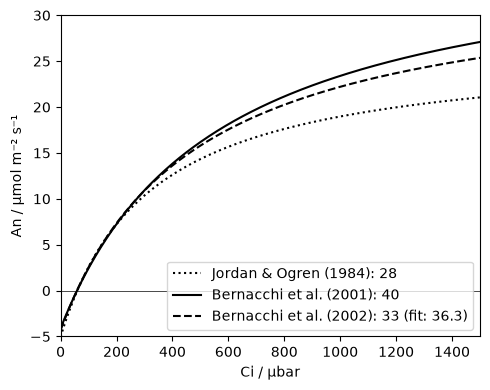

In [4]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["jo84"]["x"], tables["jo84"]["Ac_inf"], color="black", ls=":", label="Jordan & Ogren (1984): 28")
ax0.plot(tables["b01"]["x"], tables["b01"]["Ac_inf"], color="black", ls="-", label="Bernacchi et al. (2001): 40")
ax0.plot(tables["b02"]["x"], tables["b02"]["Ac_inf"], color="black", ls="--", label="Bernacchi et al. (2002): 33 (fit: 36.3)")
ax0.set_xlabel("Ci / µbar")
ax0.set_ylabel("An / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 1500)
ax0.set_ylim(-5, 30)
ax0.axhline(0, color="black", lw=0.5)
ax0.legend()
plt.tight_layout()
plt.show()

## Figure 3: Eqn 14 against Eqn 10 on measured curves

In [5]:
tables = {}

# Scan a_eq14
to_scan = pd.DataFrame({"Ci": np.linspace(0, 600, 321), "O": 210, "S_co": 2325.7874451778675, "Kc": 274.22, "Ko": 418.29, "Vcmax": 33, "Rd": -0.16})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["a_eq14"] = {
    "x": np.linspace(0, 600, 321),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

# Scan a_eq10
to_scan = pd.DataFrame({"Ci": np.linspace(0, 600, 321), "O": 210, "S_co": 2325.7874451778675, "Kc": 274.22, "Ko": 418.29, "Vcmax": 57, "Rd": -0.95, "gi": 0.1})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac"]].isna().any(axis=None)
tables["a_eq10"] = {
    "x": np.linspace(0, 600, 321),
    "Ac": frame["Ac"].to_numpy(),
}

# Scan b_eq14
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "O": 210, "S_co": 2325.7874451778675, "Kc": 274.22, "Ko": 418.29, "Vcmax": 30, "Rd": -1.07})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["b_eq14"] = {
    "x": np.linspace(0, 1600, 321),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

# Scan b_eq10
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "O": 210, "S_co": 2325.7874451778675, "Kc": 274.22, "Ko": 418.29, "Vcmax": 56, "Rd": -1.68, "gi": 0.15})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac"]].isna().any(axis=None)
tables["b_eq10"] = {
    "x": np.linspace(0, 1600, 321),
    "Ac": frame["Ac"].to_numpy(),
}

  0%|          | 0/321 [00:00<?, ?it/s]

 97%|█████████▋| 310/321 [00:00<00:00, 2625.19it/s]

100%|██████████| 321/321 [00:00<00:00, 2649.52it/s]

  0%|          | 0/321 [00:00<?, ?it/s]

100%|██████████| 321/321 [00:00<00:00, 5301.39it/s]

  0%|          | 0/321 [00:00<?, ?it/s]

100%|██████████| 321/321 [00:00<00:00, 5347.94it/s]

  0%|          | 0/321 [00:00<?, ?it/s]

100%|██████████| 321/321 [00:00<00:00, 5218.84it/s]

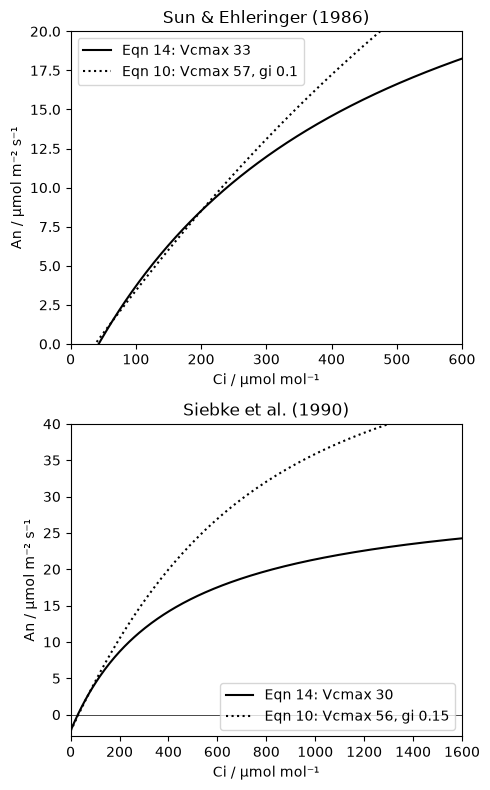

In [6]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(5, 8), squeeze=False)
ax0 = axs[0, 0]
ax0.set_title("Sun & Ehleringer (1986)")
ax0.plot(tables["a_eq14"]["x"], tables["a_eq14"]["Ac_inf"], color="black", ls="-", label="Eqn 14: Vcmax 33")
ax0.plot(tables["a_eq10"]["x"], tables["a_eq10"]["Ac"], color="black", ls=":", label="Eqn 10: Vcmax 57, gi 0.1")
ax0.set_xlabel("Ci / µmol mol⁻¹")
ax0.set_ylabel("An / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 600)
ax0.set_ylim(0, 20)
ax0.legend()
ax1 = axs[1, 0]
ax1.set_title("Siebke et al. (1990)")
ax1.plot(tables["b_eq14"]["x"], tables["b_eq14"]["Ac_inf"], color="black", ls="-", label="Eqn 14: Vcmax 30")
ax1.plot(tables["b_eq10"]["x"], tables["b_eq10"]["Ac"], color="black", ls=":", label="Eqn 10: Vcmax 56, gi 0.15")
ax1.set_xlabel("Ci / µmol mol⁻¹")
ax1.set_ylabel("An / µmol m⁻² s⁻¹")
ax1.set_xlim(0, 1600)
ax1.set_ylim(-3, 40)
ax1.axhline(0, color="black", lw=0.5)
ax1.legend()
plt.tight_layout()
plt.show()

## Figure 5: fits to ideal A–Ci curves

In [7]:
tables = {}

# Scan a_pc
to_scan = pd.DataFrame({"Ci": np.linspace(40, 240, 6), "gi": 0.2})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["An"]].isna().any(axis=None)
tables["a_pc"] = {
    "x": np.linspace(40, 240, 6),
    "An": frame["An"].to_numpy(),
}

# Scan a_poj
to_scan = pd.DataFrame({"Ci": np.linspace(300, 400, 3), "gi": 0.2})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["An"]].isna().any(axis=None)
tables["a_poj"] = {
    "x": np.linspace(300, 400, 3),
    "An": frame["An"].to_numpy(),
}

# Scan a_pj
to_scan = pd.DataFrame({"Ci": np.linspace(500, 1500, 6), "gi": 0.2})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["An"]].isna().any(axis=None)
tables["a_pj"] = {
    "x": np.linspace(500, 1500, 6),
    "An": frame["An"].to_numpy(),
}

# Scan a_eq14
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "O": 210, "S_co": 2114.35222288897, "Kc": 329.064, "Ko": 418.29, "Vcmax": 46.5, "Rd": 0.18})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["a_eq14"] = {
    "x": np.linspace(0, 1600, 321),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

# Scan a_eq15
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "O": 210, "S_co": 2114.35222288897, "Kc": 329.064, "Ko": 418.29, "Jmax": 111.1, "Rd": 0.606})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Aj_inf"]].isna().any(axis=None)
tables["a_eq15"] = {
    "x": np.linspace(0, 1600, 321),
    "Aj_inf": frame["Aj_inf"].to_numpy(),
}

# Scan a_eq10c
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "O": 210, "S_co": 2114.35222288897, "Kc": 329.064, "Ko": 418.29, "Vcmax": 59.4, "Rd": 0.088, "gi": 0.2447})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac"]].isna().any(axis=None)
tables["a_eq10c"] = {
    "x": np.linspace(0, 1600, 321),
    "Ac": frame["Ac"].to_numpy(),
}

# Scan a_eq10j
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "O": 210, "S_co": 2114.35222288897, "Kc": 329.064, "Ko": 418.29, "Jmax": 112.9, "Rd": 0.594, "gi": 0.301})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Aj"]].isna().any(axis=None)
tables["a_eq10j"] = {
    "x": np.linspace(0, 1600, 321),
    "Aj": frame["Aj"].to_numpy(),
}

# Scan b_pc
to_scan = pd.DataFrame({"Ci": np.linspace(40, 240, 6), "gi": 0.05})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["An"]].isna().any(axis=None)
tables["b_pc"] = {
    "x": np.linspace(40, 240, 6),
    "An": frame["An"].to_numpy(),
}

# Scan b_poc
to_scan = pd.DataFrame({"Ci": 300, "gi": 0.05}, index=[0])
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["An"]].isna().any(axis=None)
tables["b_poc"] = {
    "x": np.array([300]),
    "An": frame["An"].to_numpy(),
}

# Scan b_poj
to_scan = pd.DataFrame({"Ci": np.array([350,400]), "gi": 0.05})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["An"]].isna().any(axis=None)
tables["b_poj"] = {
    "x": np.array([350,400]),
    "An": frame["An"].to_numpy(),
}

# Scan b_pj
to_scan = pd.DataFrame({"Ci": np.linspace(500, 1500, 6), "gi": 0.05})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["An"]].isna().any(axis=None)
tables["b_pj"] = {
    "x": np.linspace(500, 1500, 6),
    "An": frame["An"].to_numpy(),
}

# Scan b_eq14
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "O": 210, "S_co": 2114.35222288897, "Kc": 329.064, "Ko": 418.29, "Vcmax": 24.5, "Rd": 0.156})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac_inf"]].isna().any(axis=None)
tables["b_eq14"] = {
    "x": np.linspace(0, 1600, 321),
    "Ac_inf": frame["Ac_inf"].to_numpy(),
}

# Scan b_eq15
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "O": 210, "S_co": 2114.35222288897, "Kc": 329.064, "Ko": 418.29, "Jmax": 100.5, "Rd": 0.705})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Aj_inf"]].isna().any(axis=None)
tables["b_eq15"] = {
    "x": np.linspace(0, 1600, 321),
    "Aj_inf": frame["Aj_inf"].to_numpy(),
}

# Scan b_eq10c
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "O": 210, "S_co": 2114.35222288897, "Kc": 329.064, "Ko": 418.29, "Vcmax": 59.8, "Rd": 0.048, "gi": 0.052})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac"]].isna().any(axis=None)
tables["b_eq10c"] = {
    "x": np.linspace(0, 1600, 321),
    "Ac": frame["Ac"].to_numpy(),
}

# Scan b_eq10j
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "O": 210, "S_co": 2114.35222288897, "Kc": 329.064, "Ko": 418.29, "Jmax": 113.2, "Rd": 0.595, "gi": 0.0535})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Aj"]].isna().any(axis=None)
tables["b_eq10j"] = {
    "x": np.linspace(0, 1600, 321),
    "Aj": frame["Aj"].to_numpy(),
}

  0%|          | 0/6 [00:00<?, ?it/s]

100%|██████████| 6/6 [00:00<00:00, 4097.33it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

100%|██████████| 3/3 [00:00<00:00, 3646.16it/s]

  0%|          | 0/6 [00:00<?, ?it/s]

100%|██████████| 6/6 [00:00<00:00, 4226.71it/s]

... (20 outputs left out)

  0%|          | 0/321 [00:00<?, ?it/s]

100%|██████████| 321/321 [00:00<00:00, 4873.74it/s]

  0%|          | 0/321 [00:00<?, ?it/s]

100%|██████████| 321/321 [00:00<00:00, 5053.06it/s]

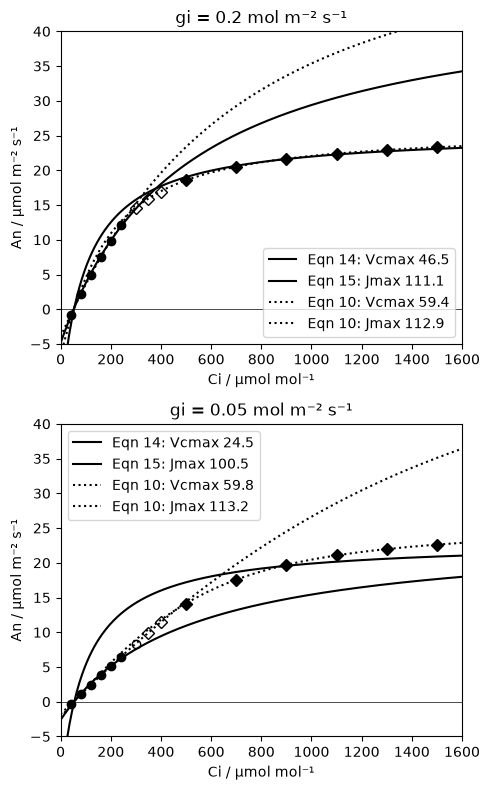

In [8]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(5, 8), squeeze=False)
ax0 = axs[0, 0]
ax0.set_title("gi = 0.2 mol m⁻² s⁻¹")
ax0.plot(tables["a_eq14"]["x"], tables["a_eq14"]["Ac_inf"], color="black", ls="-", label="Eqn 14: Vcmax 46.5")
ax0.plot(tables["a_eq15"]["x"], tables["a_eq15"]["Aj_inf"], color="black", ls="-", label="Eqn 15: Jmax 111.1")
ax0.plot(tables["a_eq10c"]["x"], tables["a_eq10c"]["Ac"], color="black", ls=":", label="Eqn 10: Vcmax 59.4")
ax0.plot(tables["a_eq10j"]["x"], tables["a_eq10j"]["Aj"], color="black", ls=":", label="Eqn 10: Jmax 112.9")
ax0.plot(tables["a_pc"]["x"], tables["a_pc"]["An"], color="black", ls="none", marker="o", markerfacecolor="black")
ax0.plot(tables["a_poj"]["x"], tables["a_poj"]["An"], color="black", ls="none", marker="D", markerfacecolor="none")
ax0.plot(tables["a_pj"]["x"], tables["a_pj"]["An"], color="black", ls="none", marker="D", markerfacecolor="black")
ax0.set_xlabel("Ci / µmol mol⁻¹")
ax0.set_ylabel("An / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 1600)
ax0.set_ylim(-5, 40)
ax0.axhline(0, color="black", lw=0.5)
ax0.legend()
ax1 = axs[1, 0]
ax1.set_title("gi = 0.05 mol m⁻² s⁻¹")
ax1.plot(tables["b_eq14"]["x"], tables["b_eq14"]["Ac_inf"], color="black", ls="-", label="Eqn 14: Vcmax 24.5")
ax1.plot(tables["b_eq15"]["x"], tables["b_eq15"]["Aj_inf"], color="black", ls="-", label="Eqn 15: Jmax 100.5")
ax1.plot(tables["b_eq10c"]["x"], tables["b_eq10c"]["Ac"], color="black", ls=":", label="Eqn 10: Vcmax 59.8")
ax1.plot(tables["b_eq10j"]["x"], tables["b_eq10j"]["Aj"], color="black", ls=":", label="Eqn 10: Jmax 113.2")
ax1.plot(tables["b_pc"]["x"], tables["b_pc"]["An"], color="black", ls="none", marker="o", markerfacecolor="black")
ax1.plot(tables["b_poc"]["x"], tables["b_poc"]["An"], color="black", ls="none", marker="o", markerfacecolor="none")
ax1.plot(tables["b_poj"]["x"], tables["b_poj"]["An"], color="black", ls="none", marker="D", markerfacecolor="none")
ax1.plot(tables["b_pj"]["x"], tables["b_pj"]["An"], color="black", ls="none", marker="D", markerfacecolor="black")
ax1.set_xlabel("Ci / µmol mol⁻¹")
ax1.set_ylabel("An / µmol m⁻² s⁻¹")
ax1.set_xlim(0, 1600)
ax1.set_ylim(-5, 40)
ax1.axhline(0, color="black", lw=0.5)
ax1.legend()
plt.tight_layout()
plt.show()

## Figure 8: O₂ response of transgenic tobacco

In [9]:
tables = {}

# Scan o2
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "gi": 0.27, "Vcmax": 36.66, "Rd": 0.66, "Kc": 306.35149812142834, "Ko": 282.6, "S_co": 1384.4986007726905, "Jmax": 1000000, "I": 1500, "O": 19.047619047619047})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac"]].isna().any(axis=None)
tables["o2"] = {
    "x": np.linspace(0, 1600, 321),
    "Ac": frame["Ac"].to_numpy(),
}

# Scan o5
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "gi": 0.27, "Vcmax": 36.66, "Rd": 0.66, "Kc": 342.3182303233063, "Ko": 282.6, "S_co": 2645.021645021645, "Jmax": 1000000, "I": 1500, "O": 47.61904761904762})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac"]].isna().any(axis=None)
tables["o5"] = {
    "x": np.linspace(0, 1600, 321),
    "Ac": frame["Ac"].to_numpy(),
}

# Scan o21
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "gi": 0.27, "Vcmax": 34.76, "Rd": 0.66, "Kc": 303.3294653957729, "Ko": 282.6, "S_co": 2266.5327786544253, "Jmax": 1000000, "I": 1500, "O": 200})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac"]].isna().any(axis=None)
tables["o21"] = {
    "x": np.linspace(0, 1600, 321),
    "Ac": frame["Ac"].to_numpy(),
}

# Scan o35
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "gi": 0.27, "Vcmax": 36.459999999999994, "Rd": 0.66, "Kc": 369.3467907782228, "Ko": 282.6, "S_co": 2304.386297560359, "Jmax": 1000000, "I": 1500, "O": 333.3333333333333})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac"]].isna().any(axis=None)
tables["o35"] = {
    "x": np.linspace(0, 1600, 321),
    "Ac": frame["Ac"].to_numpy(),
}

# Scan o50
to_scan = pd.DataFrame({"Ci": np.linspace(0, 1600, 321), "gi": 0.27, "Vcmax": 33.36, "Rd": 0.66, "Kc": 306.1414280873069, "Ko": 282.6, "S_co": 2304.361376913946, "Jmax": 1000000, "I": 1500, "O": 476.1904761904762})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Ac"]].isna().any(axis=None)
tables["o50"] = {
    "x": np.linspace(0, 1600, 321),
    "Ac": frame["Ac"].to_numpy(),
}

  0%|          | 0/321 [00:00<?, ?it/s]

 60%|█████▉    | 191/321 [00:00<00:00, 1909.33it/s]

100%|██████████| 321/321 [00:00<00:00, 2578.79it/s]

  0%|          | 0/321 [00:00<?, ?it/s]

100%|██████████| 321/321 [00:00<00:00, 5262.00it/s]

  0%|          | 0/321 [00:00<?, ?it/s]

100%|██████████| 321/321 [00:00<00:00, 5264.38it/s]

  0%|          | 0/321 [00:00<?, ?it/s]

100%|██████████| 321/321 [00:00<00:00, 5272.38it/s]

  0%|          | 0/321 [00:00<?, ?it/s]

100%|██████████| 321/321 [00:00<00:00, 5274.78it/s]

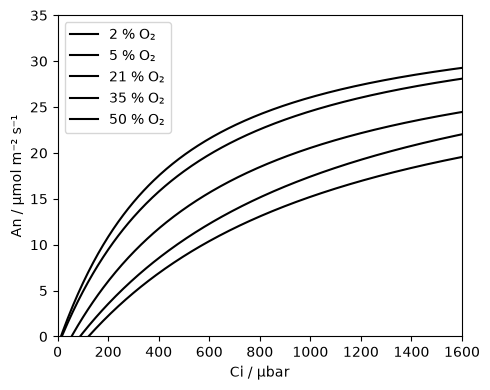

In [10]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["o2"]["x"], tables["o2"]["Ac"], color="black", ls="-", label="2 % O₂")
ax0.plot(tables["o5"]["x"], tables["o5"]["Ac"], color="black", ls="-", label="5 % O₂")
ax0.plot(tables["o21"]["x"], tables["o21"]["Ac"], color="black", ls="-", label="21 % O₂")
ax0.plot(tables["o35"]["x"], tables["o35"]["Ac"], color="black", ls="-", label="35 % O₂")
ax0.plot(tables["o50"]["x"], tables["o50"]["Ac"], color="black", ls="-", label="50 % O₂")
ax0.set_xlabel("Ci / µbar")
ax0.set_ylabel("An / µmol m⁻² s⁻¹")
ax0.set_xlim(0, 1600)
ax0.set_ylim(0, 35)
ax0.legend()
plt.tight_layout()
plt.show()

## Figure 9: O₂ dependence of Γ, Kc(1 + O/Ko) and Vcmax − Rd

In [11]:
tables = {}

# Scan line
to_scan = pd.DataFrame({"O": np.linspace(0, 500, 251), "gi": 0.27, "Vcmax": 34.85, "Rd": 0.66, "Kc": 327, "Ko": 282.6, "S_co": 2291, "Jmax": 1000000, "I": 1500})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Gamma","Km","Vcmax_minus_Rd"]].isna().any(axis=None)
tables["line"] = {
    "x": to_scan["O"].to_numpy(),
    "Gamma": frame["Gamma"].to_numpy(),
    "Km": frame["Km"].to_numpy(),
    "Vcmax_minus_Rd": frame["Vcmax_minus_Rd"].to_numpy(),
}

# Scan fits
to_scan = pd.DataFrame({"gi": np.array([0.27,0.27,0.27,0.27,0.27]), "Vcmax": np.array([36.66,36.66,34.76,36.459999999999994,33.36]), "Rd": np.array([0.66,0.66,0.66,0.66,0.66]), "Kc": np.array([306.35149812142834,342.3182303233063,303.3294653957729,369.3467907782228,306.1414280873069]), "Ko": np.array([282.6,282.6,282.6,282.6,282.6]), "S_co": np.array([1384.4986007726905,2645.021645021645,2266.5327786544253,2304.386297560359,2304.361376913946]), "Jmax": np.array([1000000,1000000,1000000,1000000,1000000]), "I": np.array([1500,1500,1500,1500,1500]), "O": np.array([19.047619047619047,47.61904761904762,200,333.3333333333333,476.1904761904762])})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Gamma","Km","Vcmax_minus_Rd"]].isna().any(axis=None)
tables["fits"] = {
    "x": np.array([19.047619047619047,47.61904761904762,200,333.3333333333333,476.1904761904762]),
    "Gamma": frame["Gamma"].to_numpy(),
    "Km": frame["Km"].to_numpy(),
    "Vcmax_minus_Rd": frame["Vcmax_minus_Rd"].to_numpy(),
}

  0%|          | 0/251 [00:00<?, ?it/s]

100%|██████████| 251/251 [00:00<00:00, 5300.93it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 5/5 [00:00<00:00, 4151.13it/s]

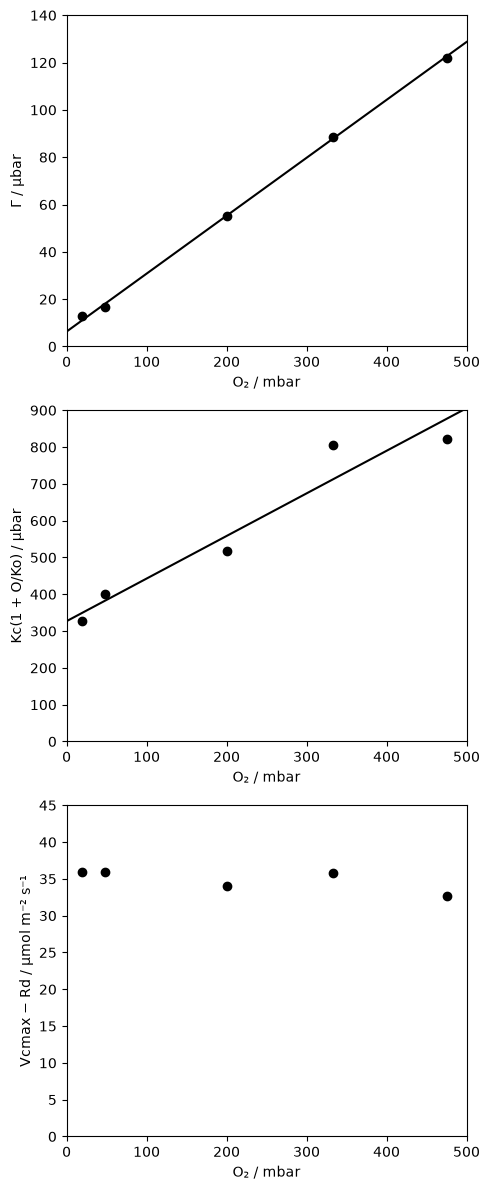

In [12]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(5, 12), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["line"]["x"], tables["line"]["Gamma"], color="black", ls="-")
ax0.plot(tables["fits"]["x"], tables["fits"]["Gamma"], color="black", ls="none", marker="o", markerfacecolor="black")
ax0.set_xlabel("O₂ / mbar")
ax0.set_ylabel("Γ / µbar")
ax0.set_xlim(0, 500)
ax0.set_ylim(0, 140)
ax1 = axs[1, 0]
ax1.plot(tables["line"]["x"], tables["line"]["Km"], color="black", ls="-")
ax1.plot(tables["fits"]["x"], tables["fits"]["Km"], color="black", ls="none", marker="o", markerfacecolor="black")
ax1.set_xlabel("O₂ / mbar")
ax1.set_ylabel("Kc(1 + O/Ko) / µbar")
ax1.set_xlim(0, 500)
ax1.set_ylim(0, 900)
ax2 = axs[2, 0]
ax2.plot(tables["fits"]["x"], tables["fits"]["Vcmax_minus_Rd"], color="black", ls="none", marker="o", markerfacecolor="black")
ax2.set_xlabel("O₂ / mbar")
ax2.set_ylabel("Vcmax − Rd / µmol m⁻² s⁻¹")
ax2.set_xlim(0, 500)
ax2.set_ylim(0, 45)
plt.tight_layout()
plt.show()